In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


df = pd.read_csv('/kaggle/input/datasets/shambhurajejagadale/student-performance-prediction-dataset/student_dataset_10000_rows.csv')
print("--- Dataset Summary ---")
print(df.info())
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Summary Statistics ---")
print(df.describe())



--- Dataset Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10000 non-null  int64  
 1   attendance             10000 non-null  int64  
 2   sleep_hours            10000 non-null  int64  
 3   internet_usage         10000 non-null  int64  
 4   assignments_completed  10000 non-null  int64  
 5   previous_score         10000 non-null  int64  
 6   exam_score             10000 non-null  float64
 7   placement_status       10000 non-null  object 
dtypes: float64(1), int64(6), object(1)
memory usage: 625.1+ KB
None

--- Missing Values ---
study_hours              0
attendance               0
sleep_hours              0
internet_usage           0
assignments_completed    0
previous_score           0
exam_score               0
placement_status         0
dtype: int64

--- Summary Statistics ---

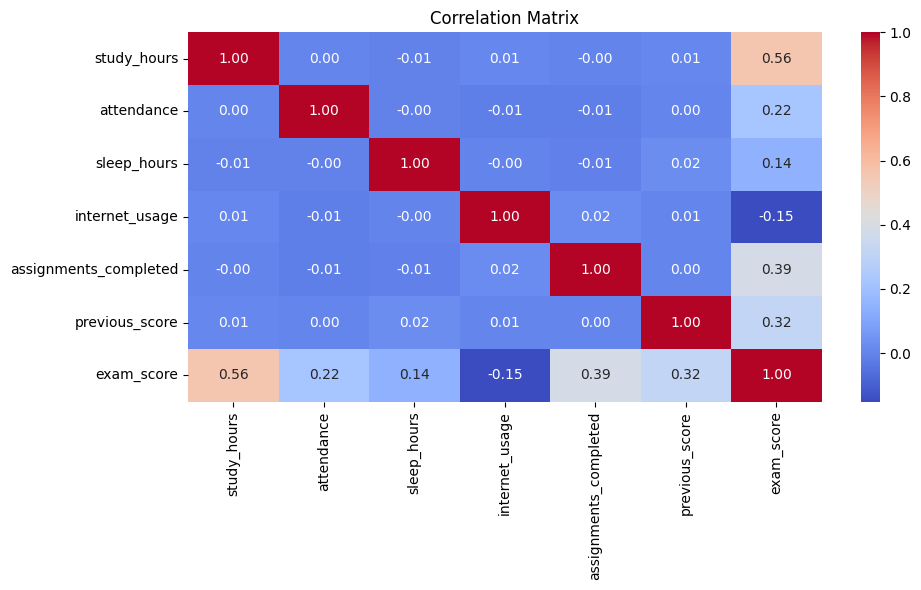


--- Scikit-Learn Linear Regression Performance ---
MSE: 41.6198
RMSE: 6.4513
MAE: 5.1310
R2 Score: 0.8188


In [18]:
# Visualizations
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

df = df.drop_duplicates()


df['study_attendance_prod'] = df['study_hours'] * df['attendance']
df['rest_study_ratio'] = df['sleep_hours'] / (df['study_hours'] + 1e-5)

X = df.drop(columns=['exam_score'])
y = df['exam_score']

num_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first'), cat_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)


y_pred = lr_model.predict(X_test_scaled)
print("\n--- Scikit-Learn Linear Regression Performance ---")
print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")

In [19]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_squared_error, r2_score

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

class LinearRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super(LinearRegressionModel, self).__init__()
        self.linear = nn.Linear(input_dim, 1)

    def forward(self, x):
        return self.linear(x)

input_dim = X_train_tensor.shape[1]

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
batch_size = 64
minibatch_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

model_minibatch = LinearRegressionModel(input_dim)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model_minibatch.parameters(), lr=0.01)

num_epochs = 100

for epoch in range(num_epochs):
    model_minibatch.train()
    for batch_x, batch_y in minibatch_loader:
        optimizer.zero_grad()
        outputs = model_minibatch(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

model_minibatch.eval()
with torch.no_grad():
    predictions_mb = model_minibatch(X_test_tensor).numpy()

print("--- Mini-Batch Gradient Descent Performance ---")
print(f"MSE: {mean_squared_error(y_test, predictions_mb):.4f}")
print(f"R2 Score: {r2_score(y_test, predictions_mb):.4f}")

--- Mini-Batch Gradient Descent Performance ---
MSE: 41.6632
R2 Score: 0.8187


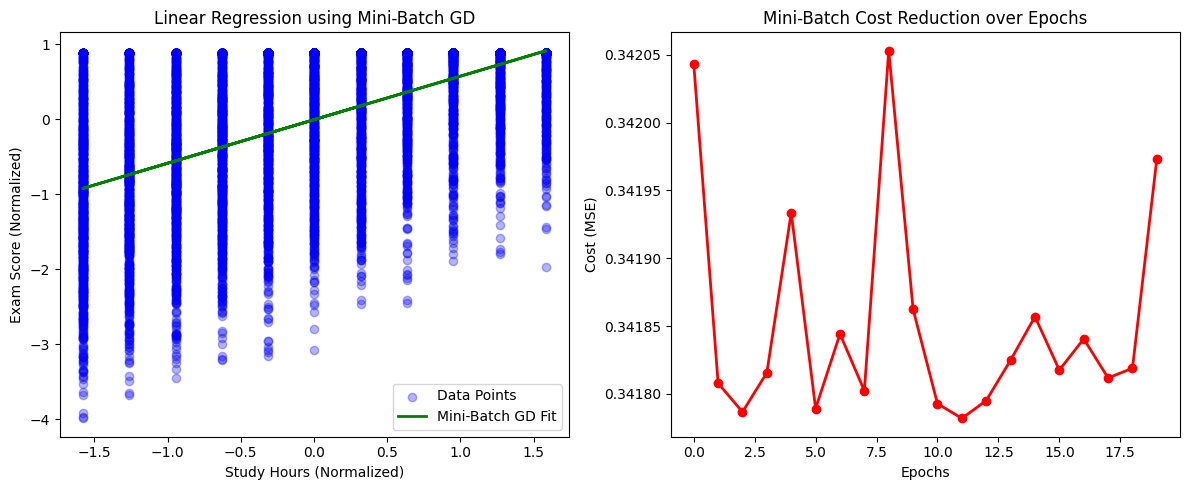

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

X = df["study_hours"].values
y = df["exam_score"].values

X_norm = (X - np.mean(X)) / np.std(X)
y_norm = (y - np.mean(y)) / np.std(y)

m = 0.0   
c = 0.0  
L = 0.01  
epochs = 20  
batch_size = 64  
n = len(X_norm)

cost_history = []

for epoch in range(epochs):
  indices = np.arange(n)
  np.random.shuffle(indices)
  X_shuffled = X_norm[indices]
  y_shuffled = y_norm[indices]

  for i in range(0, n, batch_size):
    X_batch = X_shuffled[i : i + batch_size]
    y_batch = y_shuffled[i : i + batch_size]
    curr_batch_size = len(X_batch)

    y_pred = m * X_batch + c

    D_m = (2 / curr_batch_size) * np.sum((y_pred - y_batch) * X_batch)
    D_c = (2 / curr_batch_size) * np.sum(y_pred - y_batch)

    m = m - L * D_m
    c = c - L * D_c

  y_pred_all = m * X_norm + c
  epoch_cost = (1 / (2 * n)) * np.sum((y_pred_all - y_norm) ** 2)
  cost_history.append(epoch_cost)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_norm, y_norm, color="blue", alpha=0.3, label="Data Points")
plt.plot(
    X_norm,
    m * X_norm + c,
    color="green",
    linewidth=2,
    label="Mini-Batch GD Fit",
)
plt.xlabel("Study Hours (Normalized)")
plt.ylabel("Exam Score (Normalized)")
plt.title("Linear Regression using Mini-Batch GD")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(epochs), cost_history, color="red", marker="o", linewidth=2)
plt.xlabel("Epochs")
plt.ylabel("Cost (MSE)")
plt.title("Mini-Batch Cost Reduction over Epochs")

plt.tight_layout()
plt.show()